<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%204/Latihan_Praktikum_4__Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 4 — Feature Construction, Preprocessing, Feature Selection, dan Pipeline Titanic


## Praktikum 4.1 — Persiapan Library

In [2]:
!pip -q install scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, chi2, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression, LassoCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
print("Library berhasil diimpor.")

Library berhasil diimpor.


## Praktikum 4.2 — Import Dataset Properti Sintetis

In [3]:
rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "luas_bangunan": rng.normal(120, 40, n).clip(30, 500),
    "jumlah_kamar": rng.integers(1, 6, n),
    "tipe_properti": rng.choice(["Rumah", "Ruko", "Apartemen"], n),
    "kondisi_bangunan": rng.choice(["Buruk", "Sedang", "Baik", "Sangat Baik"], n)
})

pengaruh_kondisi = df["kondisi_bangunan"].map({
    "Buruk": -100_000, "Sedang": 0, "Baik": 100_000, "Sangat Baik": 200_000
})
pengaruh_tipe = df["tipe_properti"].map({
    "Rumah": 100_000, "Ruko": 250_000, "Apartemen": 150_000
})

df["harga"] = (
    1_000_000 + df["luas_bangunan"] * 15_000
    + df["jumlah_kamar"] * 50_000 + pengaruh_kondisi
    + pengaruh_tipe + rng.normal(0, 100_000, n)
)

# Membuat missing value pada sebagian fitur
for kolom in ["luas_bangunan", "jumlah_kamar", "tipe_properti"]:
    idx = rng.choice(df.index, size=15, replace=False)
    df.loc[idx, kolom] = np.nan

print("Ukuran dataset:", df.shape)
display(df.head())
display(df.isnull().sum().to_frame("Jumlah Missing"))

Ukuran dataset: (500, 5)


,luas_bangunan,jumlah_kamar,tipe_properti,kondisi_bangunan,harga
0,132.188683,3.0,Rumah,Baik,3.341481e+06
1,78.400636,2.0,Ruko,Baik,2.658711e+06
2,150.018048,4.0,Rumah,Sedang,3.471018e+06
3,157.622589,1.0,Ruko,Sangat Baik,3.866997e+06
4,41.958592,2.0,Apartemen,Sedang,1.936433e+06


,Jumlah Missing
luas_bangunan,15
jumlah_kamar,15
tipe_properti,15
kondisi_bangunan,0
harga,0


## Praktikum 4.3 — Feature Construction & Preprocessing (ColumnTransformer)

In [4]:
# Membuat fitur baru: rasio jumlah kamar terhadap luas bangunan
df["rasio_kamar_per_luas"] = df["jumlah_kamar"] / df["luas_bangunan"]

fitur_numerik = ["luas_bangunan", "jumlah_kamar", "rasio_kamar_per_luas"]
fitur_kategorikal = ["tipe_properti"]
fitur_ordinal = ["kondisi_bangunan"]
urutan_kondisi = [["Buruk", "Sedang", "Baik", "Sangat Baik"]]

pipeline_numerik = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
pipeline_kategorikal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
pipeline_ordinal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=urutan_kondisi))
])

preprocessor = ColumnTransformer([
    ("num", pipeline_numerik, fitur_numerik),
    ("cat", pipeline_kategorikal, fitur_kategorikal),
    ("ord", pipeline_ordinal, fitur_ordinal)
])

display(df.head())

,luas_bangunan,jumlah_kamar,tipe_properti,kondisi_bangunan,harga,rasio_kamar_per_luas
0,132.188683,3.0,Rumah,Baik,3.341481e+06,0.022695
1,78.400636,2.0,Ruko,Baik,2.658711e+06,0.025510
2,150.018048,4.0,Rumah,Sedang,3.471018e+06,0.026663
3,157.622589,1.0,Ruko,Sangat Baik,3.866997e+06,0.006344
4,41.958592,2.0,Apartemen,Sedang,1.936433e+06,0.047666


## Praktikum 4.4 — Training Model (Pipeline Lengkap)

In [5]:
X = df.drop(columns=["harga"])
y = df["harga"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(n_estimators=200, random_state=42))
])
pipeline.fit(X_train, y_train)
print("Training selesai.")
print("Data training:", X_train.shape, "| Data testing:", X_test.shape)

Training selesai.
Data training: (400, 5) | Data testing: (100, 5)


## Praktikum 4.5 — Evaluasi Model

In [6]:
y_pred = pipeline.predict(X_test)

print("R2 Score :", round(r2_score(y_test, y_pred), 3))
print("MAE      :", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))

hasil_prediksi = pd.DataFrame({
    "Harga Aktual": y_test.values,
    "Harga Prediksi": y_pred
})
display(hasil_prediksi.head(10).round(2))

R2 Score : 0.916
MAE      : 127075.68
RMSE     : 173653.95


,Harga Aktual,Harga Prediksi
0,3367833.42,3385679.81
1,3148654.58,3299682.41
2,3551996.20,3478169.83
3,4444398.04,4397114.80
4,2605618.19,2487921.48
5,3880217.41,3597798.96
6,2026708.53,1896159.02
7,3450356.22,3590177.98
8,3456345.31,3674217.14
9,3194159.56,3035800.74


## Praktikum 4.6 — Visualisasi Harga Aktual dan Prediksi

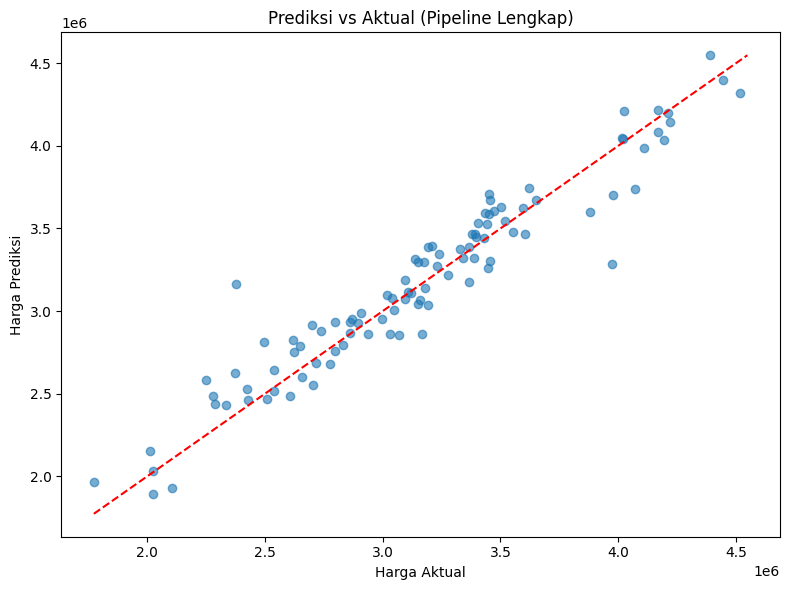

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Harga Aktual")
plt.ylabel("Harga Prediksi")
plt.title("Prediksi vs Aktual (Pipeline Lengkap)")
nilai_min = min(y_test.min(), y_pred.min())
nilai_maks = max(y_test.max(), y_pred.max())
plt.plot([nilai_min, nilai_maks], [nilai_min, nilai_maks], "r--")
plt.tight_layout()
plt.show()

## 4.15 — Interpretasi Praktikum Utama

Preprocessing (imputasi, scaling, dan encoding) digabungkan dengan model dalam satu `Pipeline`. Dengan demikian, saat data baru diprediksi, tahapan preprocessing yang sama otomatis diterapkan. Pipeline juga membantu mengurangi risiko data leakage karena preprocessing dipelajari dari data training.

## Latihan Praktikum 1 — Membandingkan Feature Selection

**Tujuan:** membandingkan tiga metode seleksi fitur pada dataset klasifikasi. Latihan menggunakan fitur Titanic (tanpa kolom target) jika file CSV sudah dimuat, agar contoh seleksi fitur relevan dengan klasifikasi. Metode yang dibandingkan:
1. SelectKBest dengan `chi2` (fitur hasil encoding harus non-negatif).
2. RFE dengan Logistic Regression.
3. Embedded selection dengan Logistic Regression penalti L1.

**Catatan konsep:** Lasso adalah metode regresi. Karena target Titanic berupa kelas 0/1, pendekatan embedded yang sesuai untuk klasifikasi adalah Logistic Regression dengan penalti L1, yang juga dapat membuat koefisien fitur menjadi nol.

In [8]:
# Muat CSV Titanic. Jika belum ada di sesi Colab, akan muncul dialog upload.
import os
csv_candidates = ["Titanic-Dataset.csv", "Titanic-Dataset(1).csv"]

csv_path = next((f for f in csv_candidates if os.path.exists(f)), None)

if csv_path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_path = next(
            (f for f in uploaded.keys() if f.lower().endswith(".csv")), None
        )
    except ImportError:
        raise FileNotFoundError(
            "Letakkan Titanic-Dataset.csv di folder kerja, atau upload file CSV di Google Colab."
        )

if csv_path is None:
    raise FileNotFoundError("File CSV Titanic tidak ditemukan.")

titanic = pd.read_csv(csv_path)
print("File digunakan:", csv_path)
print("Ukuran dataset:", titanic.shape)
display(titanic.head())

File digunakan: Titanic-Dataset.csv
Ukuran dataset: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
# Persiapan fitur klasifikasi untuk latihan feature selection
# Fitur yang digunakan: Pclass, Sex, Age, SibSp, Parch, Fare, Embarked
kolom_fitur = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
target = "Survived"

data_fs = titanic[kolom_fitur + [target]].copy()
data_fs[target] = pd.to_numeric(data_fs[target], errors="coerce")
data_fs = data_fs.dropna(subset=[target])
X_fs = data_fs[kolom_fitur]
y_fs = data_fs[target].astype(int)

num_cols_fs = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_cols_fs = ["Sex", "Embarked"]

# Imputasi numerik dan kategorikal, lalu one-hot encoding.
# Tidak menggunakan StandardScaler agar hasil chi2 tetap non-negatif.
prep_fs = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols_fs),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols_fs)
])

X_train_fs, X_test_fs, y_train_fs, y_test_fs = train_test_split(
    X_fs, y_fs, test_size=0.2, random_state=42, stratify=y_fs
)

X_train_fs_p = prep_fs.fit_transform(X_train_fs)
X_test_fs_p = prep_fs.transform(X_test_fs)
feature_names_fs = prep_fs.get_feature_names_out()

# Sparse matrix ke dense array untuk konsistensi metode seleksi
X_train_fs_p = X_train_fs_p.toarray() if hasattr(X_train_fs_p, "toarray") else X_train_fs_p
X_test_fs_p = X_test_fs_p.toarray() if hasattr(X_test_fs_p, "toarray") else X_test_fs_p

print("Jumlah fitur setelah preprocessing:", len(feature_names_fs))
print("Bentuk data training:", X_train_fs_p.shape)

Jumlah fitur setelah preprocessing: 10
Bentuk data training: (712, 10)


In [ ]:
# Metode 1: SelectKBest dengan Chi-Square
k = min(8, X_train_fs_p.shape[1])
selector_kbest = SelectKBest(score_func=chi2, k=k)
Xtr_kbest = selector_kbest.fit_transform(X_train_fs_p, y_train_fs)
Xte_kbest = selector_kbest.transform(X_test_fs_p)

model_kbest = LogisticRegression(max_iter=2000)
model_kbest.fit(Xtr_kbest, y_train_fs)
pred_kbest = model_kbest.predict(Xte_kbest)
fitur_kbest = feature_names_fs[selector_kbest.get_support()]

# Metode 2: RFE dengan Logistic Regression
estimator_rfe = LogisticRegression(max_iter=2000)
selector_rfe = RFE(estimator=estimator_rfe, n_features_to_select=k)
Xtr_rfe = selector_rfe.fit_transform(X_train_fs_p, y_train_fs)
Xte_rfe = selector_rfe.transform(X_test_fs_p)

model_rfe = LogisticRegression(max_iter=2000)
model_rfe.fit(Xtr_rfe, y_train_fs)
pred_rfe = model_rfe.predict(Xte_rfe)
fitur_rfe = feature_names_fs[selector_rfe.get_support()]

# Metode 3: Embedded — Logistic Regression dengan penalti L1
model_l1 = LogisticRegression(
    penalty="l1", solver="liblinear", C=0.5, max_iter=3000
)
model_l1.fit(X_train_fs_p, y_train_fs)
pred_l1 = model_l1.predict(X_test_fs_p)
fitur_l1 = feature_names_fs[np.abs(model_l1.coef_[0]) > 1e-8]

hasil_seleksi = pd.DataFrame([
    {
        "Metode": "SelectKBest (Chi2)",
        "Jumlah fitur": len(fitur_kbest),
        "Accuracy": accuracy_score(y_test_fs, pred_kbest),
        "Precision": precision_score(y_test_fs, pred_kbest, zero_division=0),
        "Recall": recall_score(y_test_fs, pred_kbest, zero_division=0),
        "F1-Score": f1_score(y_test_fs, pred_kbest, zero_division=0)
    },
    {
        "Metode": "RFE",
        "Jumlah fitur": len(fitur_rfe),
        "Accuracy": accuracy_score(y_test_fs, pred_rfe),
        "Precision": precision_score(y_test_fs, pred_rfe, zero_division=0),
        "Recall": recall_score(y_test_fs, pred_rfe, zero_division=0),
        "F1-Score": f1_score(y_test_fs, pred_rfe, zero_division=0)
    },
    {
        "Metode": "Embedded (L1)",
        "Jumlah fitur": len(fitur_l1),
        "Accuracy": accuracy_score(y_test_fs, pred_l1),
        "Precision": precision_score(y_test_fs, pred_l1, zero_division=0),
        "Recall": recall_score(y_test_fs, pred_l1, zero_division=0),
        "F1-Score": f1_score(y_test_fs, pred_l1, zero_division=0)
    }
]).set_index("Metode")

display(hasil_seleksi.round(3))
print("Fitur SelectKBest:", list(fitur_kbest))
print("Fitur RFE:", list(fitur_rfe))
print("Fitur Embedded L1:", list(fitur_l1))
print("\nMetode F1-Score tertinggi:", hasil_seleksi["F1-Score"].idxmax())

### Interpretasi Latihan 1

- **SelectKBest** memilih fitur dengan skor hubungan statistik tertinggi terhadap target.
- **RFE** melakukan eliminasi fitur bertahap berdasarkan bobot model.
- **Embedded L1** memilih fitur saat proses training; koefisien yang menjadi nol dianggap tidak terpilih.
- Bandingkan Accuracy, Precision, Recall, dan terutama F1-Score pada tabel. Metode terbaik ditentukan berdasarkan hasil data uji, bukan asumsi bahwa satu metode selalu unggul.

## Latihan Praktikum 2 — Pipeline Lengkap pada Dataset Titanic

Dataset yang digunakan adalah **Titanic-Dataset.csv** yang kamu unggah. Target klasifikasi adalah `Survived` (0 = tidak selamat, 1 = selamat). Fitur numerik: `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`. Fitur kategorikal: `Sex`, `Embarked`. Kolom identitas/nama/tiket/kabin tidak digunakan dalam model dasar.

In [10]:
# Pembagian data training dan testing
X_titanic = titanic[["Pclass", "Age", "SibSp", "Parch", "Fare", "Sex", "Embarked"]].copy()
y_titanic = pd.to_numeric(titanic["Survived"], errors="coerce")

valid = y_titanic.notna()
X_titanic = X_titanic.loc[valid]
y_titanic = y_titanic.loc[valid].astype(int)

fitur_numerik_t = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
fitur_kategorikal_t = ["Sex", "Embarked"]

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_titanic, y_titanic, test_size=0.2,
    random_state=42, stratify=y_titanic
)

print("Jumlah data training:", len(X_train_t))
print("Jumlah data testing:", len(X_test_t))
print("\nDistribusi target:")
display(y_titanic.value_counts().rename(index={0:"Tidak selamat", 1:"Selamat"}).to_frame("Jumlah"))

Jumlah data training: 712
Jumlah data testing: 179

Distribusi target:


,Jumlah
Survived,
Tidak selamat,549
Selamat,342


In [11]:
# Pipeline preprocessing numerik
numeric_pipeline_t = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline preprocessing kategorikal
categorical_pipeline_t = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_t = ColumnTransformer([
    ("num", numeric_pipeline_t, fitur_numerik_t),
    ("cat", categorical_pipeline_t, fitur_kategorikal_t)
])

# Pipeline end-to-end: preprocessing + Random Forest Classifier
pipeline_titanic = Pipeline([
    ("preprocessing", preprocessor_t),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced"
    ))
])

pipeline_titanic.fit(X_train_t, y_train_t)
pred_titanic = pipeline_titanic.predict(X_test_t)

print("Akurasi:", round(accuracy_score(y_test_t, pred_titanic), 3))
print("\nClassification Report:")
print(classification_report(
    y_test_t, pred_titanic,
    target_names=["Tidak selamat", "Selamat"],
    zero_division=0
))

Akurasi: 0.816

Classification Report:
               precision    recall  f1-score   support

Tidak selamat       0.82      0.89      0.86       110
      Selamat       0.80      0.70      0.74        69

     accuracy                           0.82       179
    macro avg       0.81      0.79      0.80       179
 weighted avg       0.81      0.82      0.81       179



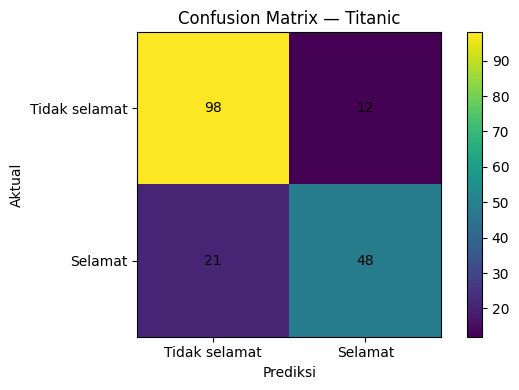

In [12]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test_t, pred_titanic)
plt.figure(figsize=(6, 4))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix — Titanic")
plt.colorbar()
plt.xticks([0, 1], ["Tidak selamat", "Selamat"])
plt.yticks([0, 1], ["Tidak selamat", "Selamat"])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.tight_layout()
plt.show()

### Interpretasi Latihan 2

Pipeline menggabungkan imputasi, scaling, One-Hot Encoding, dan Random Forest Classifier. Dengan pipeline, data baru akan melewati preprocessing yang sama seperti data training. Nilai akurasi dan classification report pada output menunjukkan performa model pada data uji. Perhatikan precision, recall, dan F1-Score per kelas, karena akurasi saja belum cukup untuk menilai model klasifikasi.

## Kesimpulan

1. Feature construction menambahkan informasi baru melalui fitur turunan.
2. `ColumnTransformer` menerapkan preprocessing berbeda sesuai jenis kolom.
3. `Pipeline` menggabungkan preprocessing dan model dalam satu alur serta membantu mencegah data leakage.
4. SelectKBest, RFE, dan Embedded L1 mempunyai pendekatan seleksi fitur berbeda; evaluasi pada data uji digunakan untuk membandingkannya.
5. Pipeline Titanic dapat menangani data numerik dan kategorikal, missing values, serta klasifikasi penumpang.

**Catatan:** hasil evaluasi yang benar adalah angka yang muncul saat notebook dijalankan dengan file Titanic yang disertakan. Jangan menyalin angka perkiraan.